# Figure — Intrinsic dimension along transdifferentiation and reprogramming

**Dataset** [GSE112004](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE112004) —
"Single cell RNA-seq identifies the origins of heterogeneity in efficient cell
transdifferentiation and reprogramming". Mouse pre-B cells, 3,840 cells.

> Francesconi M, Di Stefano B, Berenguer C, de Andrés-Aguayo L, Plana-Carmona M,
> Mendez-Lago M, Guillaumet-Adkins A, Rodriguez-Esteban G, Gut M, Gut IG, Heyn H, Lehner B,
> Graf T. *eLife* 2019;8:e41627. [doi:10.7554/eLife.41627](https://doi.org/10.7554/eLife.41627)

The same starting cell type is pushed down **two different routes**:

| Trajectory | Induction | Treatment | Time points |
|---|---|---|---|
| **iMac** | C/EBPα | transdifferentiation | 42h, 66h, 114h |
| **iPSC** | OSKM | reprogramming | day 2, day 4, day 6, day 8 |

That makes it a clean test: one route ends in a differentiated macrophage, the other in a
pluripotent cell, from the same origin. If the intrinsic dimension tracks potency it should
fall along one and rise along the other.

**The three shared early time points (0h, 6h, 18h) are not plotted** — they precede the fate
split and carry no trajectory label. 2,688 cells remain.

Input: `Input_transdiff_reprog.csv`. All scores 0–1.
Output: `figures/` (600 dpi PNG + vector PDF) and `source_data/`.


In [6]:
import os
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal, rankdata, norm, pearsonr
from statsmodels.stats.multitest import multipletests

FIG, SRC = "figures", "source_data"
os.makedirs(FIG, exist_ok=True); os.makedirs(SRC, exist_ok=True)

DPI = 600
mpl.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": DPI, "savefig.bbox": "tight",
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "axes.linewidth": 0.9, "axes.labelsize": 12, "axes.titlesize": 13,
    "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10,
})
sns.set_theme(style="white", context="paper", rc=mpl.rcParams)

# Titles on or off. Journals want bare panels with the caption carrying the text.
SHOW_TITLES = True


def put_title(ax, text, fontsize=13):
    if SHOW_TITLES:
        ax.set_title(text, fontsize=fontsize)


def minmax(x):
    x = np.asarray(x, dtype=float)
    lo, hi = np.nanmin(x), np.nanmax(x)
    return (x - lo) / (hi - lo)


def save(fig, name):
    fig.savefig(f"{FIG}/{name}.png", dpi=DPI)
    fig.savefig(f"{FIG}/{name}.pdf")
    print(f"saved  {FIG}/{name}.png  +  .pdf")


def dunn(data, order):
    """Dunn's post-hoc: pooled ranks, tie correction, BH-FDR, rank-biserial."""
    allv = np.concatenate([data[g] for g in order])
    grp  = np.concatenate([np.repeat(g, len(data[g])) for g in order])
    ranks, N = rankdata(allv), len(allv)
    mean_rank = pd.DataFrame({"g": grp, "r": ranks}).groupby("g")["r"].mean()
    n = {g: len(data[g]) for g in order}
    _, tc = np.unique(allv, return_counts=True)
    tie = 1 - np.sum(tc ** 3 - tc) / (N ** 3 - N)

    def rb(x, y):
        r = rankdata(np.concatenate([x, y]))
        U = r[:len(x)].sum() - len(x) * (len(x) + 1) / 2
        return 2 * U / (len(x) * len(y)) - 1

    rows = []
    for a, b in combinations(order, 2):
        se = np.sqrt((N * (N + 1) / 12) * (1 / n[a] + 1 / n[b]) * tie)
        z = (mean_rank[a] - mean_rank[b]) / se
        rows.append({"group1": a, "group2": b, "z": z, "p": 2 * norm.sf(abs(z)),
                     "median_difference": np.median(data[a]) - np.median(data[b]),
                     "rank_biserial": rb(data[a], data[b])})
    out = pd.DataFrame(rows)
    out["q"] = multipletests(out["p"], method="fdr_bh")[1]
    out["signif"] = pd.cut(out["q"], [-np.inf, 1e-4, 1e-3, 1e-2, 5e-2, np.inf],
                           labels=["****", "***", "**", "*", "ns"])
    return out


---

## 1 · How the ID was calculated

**Per-cell** IDEAS, `method="local_2nn"`, **k = 100** — one ID per cell, from that cell's own
neighbourhood. This is the only ID used in the figure.

**IDEAS** — <https://github.com/maddalenastn/IDEAS>.
Staiano M, Cirone N, Biondo M, Osella M, Scialdone A. *bioRxiv* 2025.
[doi:10.1101/2025.07.21.665922](https://doi.org/10.1101/2025.07.21.665922)

Verbatim from the run script:

```python
import sys
sys.path.insert(0, "/workspace/IDEAS/computeID")

import anndata as ad
from functions_IDEAS import compute_ID

adata = ad.read_h5ad("/mnt/results/GSE112004_raw.h5ad")   # 3840 cells x 28874, raw UMI

id_local = compute_ID(
    adata,
    group="all",
    method="local_2nn",
    id_score=True,              # IDEAS rescales to 0-1 itself
    n_neighbors=100,
    normalization=True,
    norm_sum=int(1e6),
)

adata.obs["ID_local_2nn"] = id_local.iloc[:, 0].values
```

Note `id_score=True` here, unlike the other figures in this repository — IDEAS scaled the
values to 0–1 across all 3,840 cells before they were written out. `the input builder` rescales
again over the 2,688 plotted cells so each panel spans the full range. Both steps are linear,
so no statistic is affected.

**A global 2NN ID also exists** in the source file (`ID_global_2nn`, one value per time point
repeated across its cells, 30 subsamples). It is **not plotted here** — the figure uses the
per-cell local ID only.


---

## 2 · How the signalling entropy was calculated

**CCAT** — the fast approximation to signalling entropy — `SCENT::CompCCAT` on the
log-normalised matrix against a protein–protein interaction network.

> Teschendorff AE, Enver T. Single-cell entropy for accurate estimation of differentiation
> potency from a cell's transcriptome. *Nat Commun* 2017;8:15599.
> [doi:10.1038/ncomms15599](https://doi.org/10.1038/ncomms15599)

Code used: <https://github.com/Zaoqu-Liu/SCENT>, an Rcpp-optimised fork of the authors'
original package <https://github.com/aet21/SCENT>. Wrapper in `../src/scent/`.


In [7]:
INPUT = "Input_transdiff_reprog.csv"

TRAJ  = ["iMac", "iPSC"]
STEPS = {"iMac": ["42h", "66h", "114h"],
         "iPSC": ["day 2", "day 4", "day 6", "day 8"]}
COL   = {"iMac": "#E1812C", "iPSC": "#3274A1"}      # orange / blue, as in the draft

ID_LABEL      = "Local intrinsic dimension (2NN)"
ENTROPY_LABEL = "CCAT signalling entropy"

cells = pd.read_csv(INPUT, index_col=0)

print(f"{len(cells):,} cells across {len(TRAJ)} trajectories")
print()
print(cells.groupby(["trajectory", "time_point"], observed=True)
      .size().rename("n").to_string())
display(cells.head(3))


2,688 cells across 2 trajectories

trajectory  time_point
iMac        114h          384
            42h           384
            66h           384
iPSC        day 2         384
            day 4         384
            day 6         384
            day 8         384


,fate,trajectory,time_point,day,treatment,induction,ID_score_raw,ID_score,signalling_entropy_raw,signalling_entropy
cell_barcode,,,,,,,,,,
030U_MSCB-001,iPSCs,iPSC,day 6,6.0,reprogramming,OSKM,0.263866,0.423642,0.245580,0.809081
030U_MSCB-002,iPSCs,iPSC,day 6,6.0,reprogramming,OSKM,0.246733,0.396135,0.270631,0.907357
030U_MSCB-003,iPSCs,iPSC,day 6,6.0,reprogramming,OSKM,0.400802,0.643494,0.179203,0.548684


---

## 3 · Panels 1–2 — ID score and signalling entropy along the two trajectories

One figure per score, split into two panels sharing a y-axis: the iMac trajectory on the
left, the iPSC trajectory on the right. Violin with the interquartile box inside, and the
**medians joined by a dashed line** so the direction of travel is readable at a glance.


/var/folders/7p/x3y7xk251jvf0cl1kmd__y6m0000gn/T/ipykernel_68200/3243032476.py:47: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


saved  figures/panel01_id_across_trajectories.png  +  .pdf


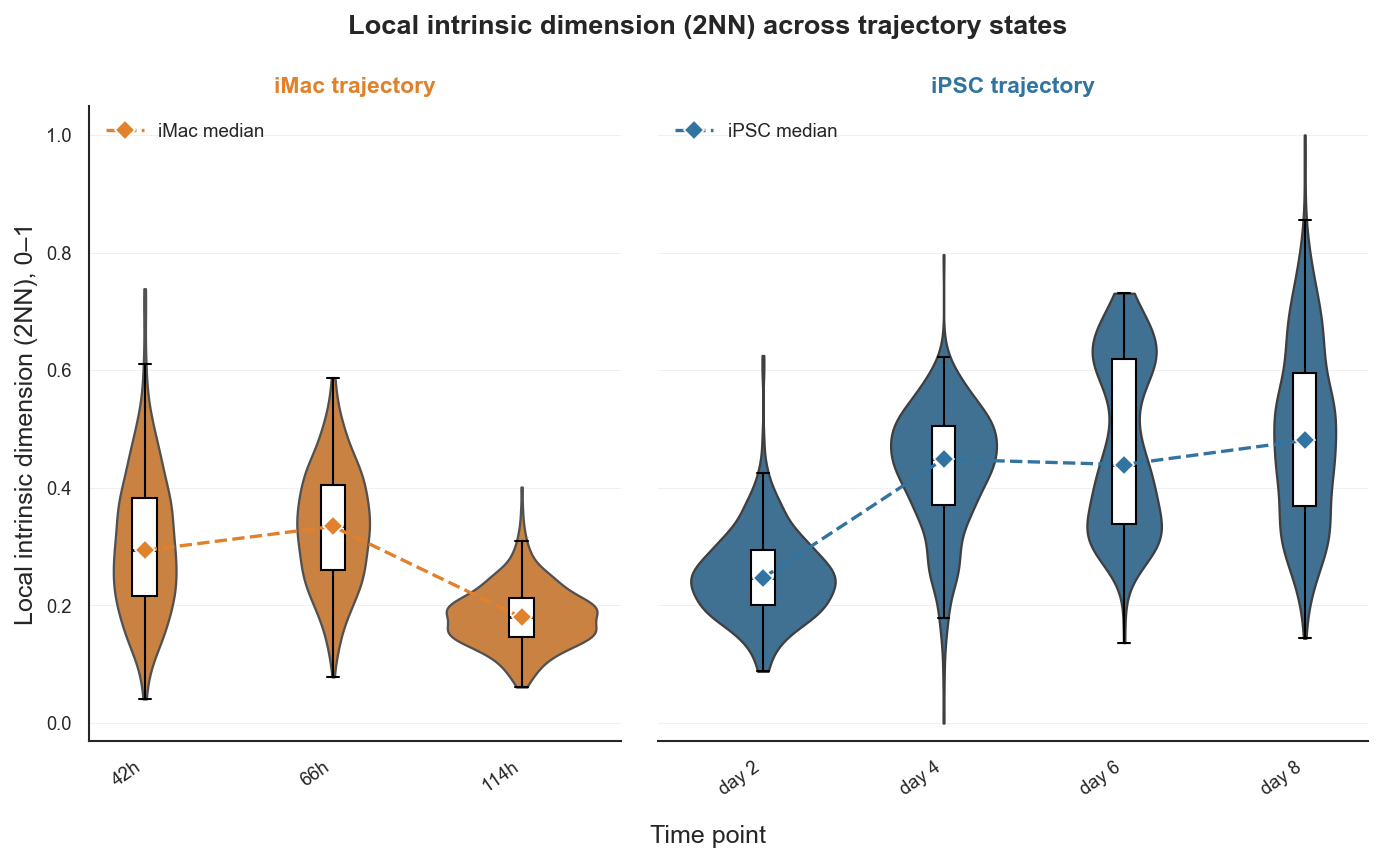

trajectory time_point   n  median   mean     sd
      iMac        42h 384  0.2937 0.3051 0.1190
      iMac        66h 384  0.3343 0.3335 0.0984
      iMac       114h 384  0.1798 0.1819 0.0520
      iPSC      day 2 384  0.2468 0.2517 0.0742
      iPSC      day 4 384  0.4487 0.4317 0.1048
      iPSC      day 6 384  0.4395 0.4736 0.1430
      iPSC      day 8 384  0.4807 0.4893 0.1505


In [8]:
def trajectory_panel(score, ylabel, title, name):
    """Two trajectories side by side, violins with the medians joined."""
    fig, axes = plt.subplots(
        1, 2, figsize=(11, 5.5), sharey=True,
        gridspec_kw={"width_ratios": [len(STEPS["iMac"]), len(STEPS["iPSC"])], "wspace": 0.06})

    stats = []
    for ax, traj in zip(axes, TRAJ):
        order = STEPS[traj]
        d = cells[cells["trajectory"] == traj]
        med = d.groupby("time_point", observed=True)[score].median().reindex(order)

        sns.violinplot(data=d, x="time_point", y=score, order=order,
                       inner=None, cut=0, linewidth=1.1, color=COL[traj], ax=ax)
        sns.boxplot(data=d, x="time_point", y=score, order=order,
                    width=0.13, showfliers=False,
                    boxprops=dict(facecolor="white", edgecolor="black", linewidth=1.0),
                    whiskerprops=dict(color="black", linewidth=1.0),
                    capprops=dict(color="black", linewidth=1.0),
                    medianprops=dict(color="black", linewidth=1.2), ax=ax)

        # the median trajectory — the point of the panel
        ax.plot(np.arange(len(order)), med.values, color=COL[traj], linestyle="--",
                linewidth=1.6, marker="D", markersize=7, markeredgecolor="white",
                markeredgewidth=0.8, zorder=6, label=f"{traj} median")

        ax.set_xticks(range(len(order)))
        ax.set_xticklabels(order, rotation=35, ha="right")
        ax.set_xlabel("")
        ax.set_title(f"{traj} trajectory", fontsize=11, color=COL[traj], fontweight="bold")
        ax.legend(frameon=False, loc="upper left", fontsize=9)
        ax.set_ylim(-0.03, 1.05)
        ax.grid(axis="y", linewidth=0.4, alpha=0.35)
        ax.set_axisbelow(True)
        sns.despine(ax=ax, left=(traj != "iMac"))

        for t in order:
            v = d.loc[d["time_point"] == t, score]
            stats.append({"trajectory": traj, "time_point": t, "n": len(v),
                          "median": v.median(), "mean": v.mean(), "sd": v.std()})

    axes[0].set_ylabel(ylabel, fontsize=12)
    axes[1].set_ylabel("")
    if SHOW_TITLES:
        fig.suptitle(title, fontsize=13, fontweight="bold", y=0.99)
    fig.supxlabel("Time point", fontsize=12, y=-0.02)
    fig.tight_layout()
    save(fig, name)
    plt.show()

    tab = pd.DataFrame(stats).round(4)
    print(tab.to_string(index=False))
    tab.to_csv(f"{SRC}/{name}.csv", index=False)
    return tab


id_tab = trajectory_panel(
    "ID_score", "Local intrinsic dimension (2NN), 0–1",
    "Local intrinsic dimension (2NN) across trajectory states",
    "panel01_id_across_trajectories")


/var/folders/7p/x3y7xk251jvf0cl1kmd__y6m0000gn/T/ipykernel_68200/3243032476.py:47: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


saved  figures/panel02_entropy_across_trajectories.png  +  .pdf


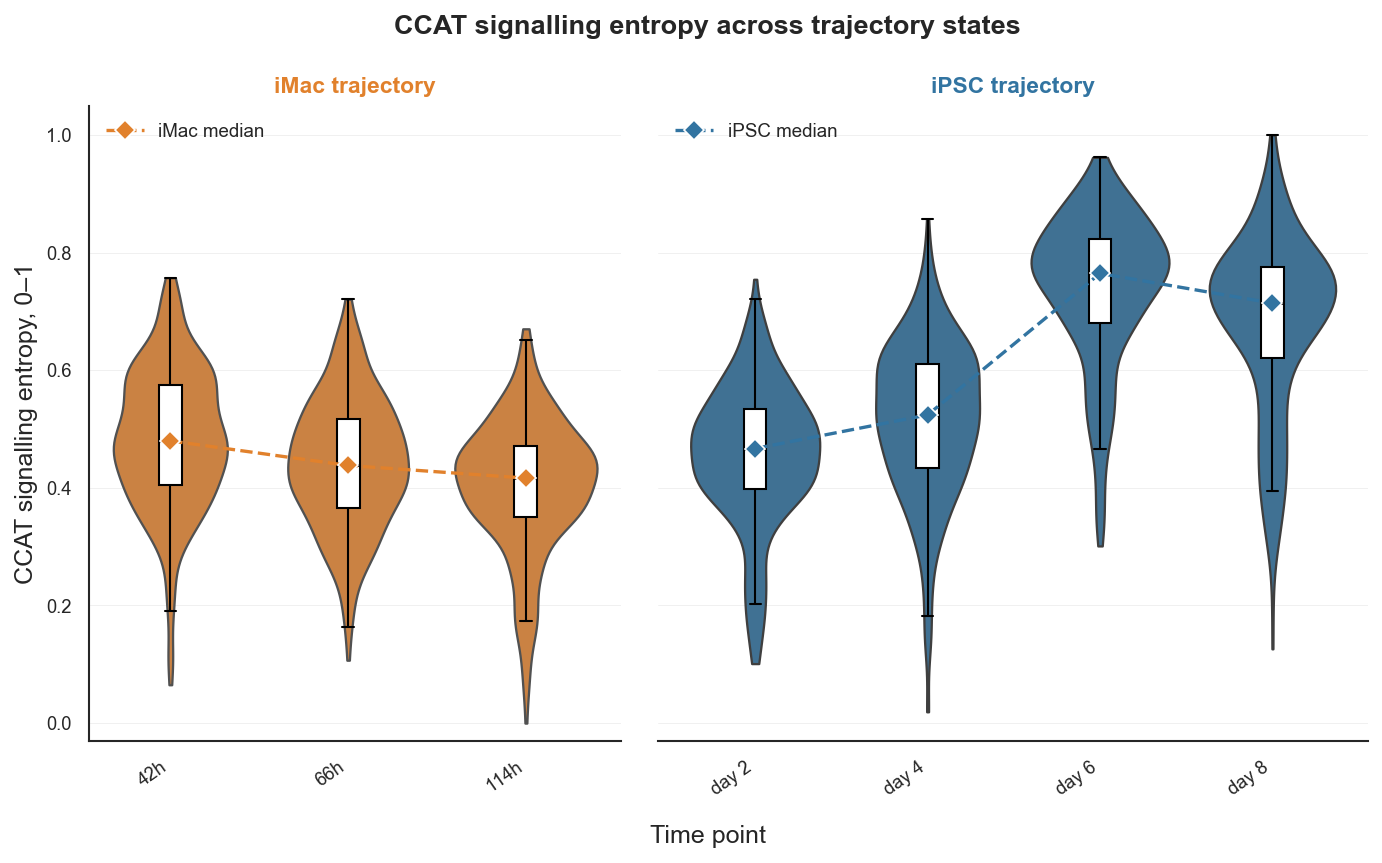

trajectory time_point   n  median   mean     sd
      iMac        42h 384  0.4798 0.4835 0.1194
      iMac        66h 384  0.4380 0.4415 0.1112
      iMac       114h 384  0.4165 0.4038 0.1128
      iPSC      day 2 384  0.4668 0.4553 0.1189
      iPSC      day 4 384  0.5240 0.5153 0.1319
      iPSC      day 6 384  0.7645 0.7377 0.1278
      iPSC      day 8 384  0.7140 0.6815 0.1509


In [9]:
ent_tab = trajectory_panel(
    "signalling_entropy", "CCAT signalling entropy, 0–1",
    "CCAT signalling entropy across trajectory states",
    "panel02_entropy_across_trajectories")


---

## 4 · Statistics

Two questions, so two tests.

**Within each trajectory** — does the score move across time points? Kruskal-Wallis across
that trajectory's time points, then Dunn with BH-FDR.

**Between trajectories** — do the two routes end up in different places? Mann-Whitney on the
last time point of each (114h vs day 8), with rank-biserial as the effect size.


In [10]:
from scipy.stats import mannwhitneyu

rows = []
for score, label in [("ID_score", ID_LABEL), ("signalling_entropy", ENTROPY_LABEL)]:
    print(f"════ {label} ════\n")
    for traj in TRAJ:
        order = STEPS[traj]
        d = cells[cells["trajectory"] == traj]
        data = {t: d.loc[d["time_point"] == t, score].values for t in order}
        H, p = kruskal(*[data[t] for t in order])
        print(f"{traj}: Kruskal-Wallis H = {H:.2f}, p = {p:.3e}  "
              f"(n = {sum(len(v) for v in data.values()):,})")
        tab = dunn(data, order)
        print(tab.to_string(index=False))
        print()
        rows.append(dict(score=label, test=f"Kruskal-Wallis within {traj}", stat=H, p=p))
        tab.assign(score=label, trajectory=traj).to_csv(
            f"{SRC}/stats_dunn_{score}_{traj}.csv", index=False)

    # endpoint comparison
    a = cells[(cells.trajectory == "iMac") & (cells.time_point == "114h")][score]
    b = cells[(cells.trajectory == "iPSC") & (cells.time_point == "day 8")][score]
    U, p_mw = mannwhitneyu(a, b, alternative="two-sided")
    rb = 2 * U / (len(a) * len(b)) - 1
    print(f"endpoint, iMac 114h vs iPSC day 8:  U = {U:,.0f}  p = {p_mw:.3e}  "
          f"rank-biserial = {rb:.3f}  (median {a.median():.3f} vs {b.median():.3f})\n")
    rows.append(dict(score=label, test="Mann-Whitney, iMac 114h vs iPSC day 8",
                     stat=U, p=p_mw, rank_biserial=rb,
                     median_iMac=a.median(), median_iPSC=b.median()))

omnibus = pd.DataFrame(rows)
omnibus.to_csv(f"{SRC}/stats_omnibus.csv", index=False)
display(omnibus)


════ Local intrinsic dimension (2NN) ════

iMac: Kruskal-Wallis H = 433.62, p = 6.931e-95  (n = 1,152)
group1 group2         z            p  median_difference  rank_biserial            q signif
   42h    66h -4.056074 4.990442e-05          -0.040688      -0.168396 4.990442e-05   ****
   42h   114h 15.660251 2.827792e-55           0.113805       0.652113 4.241688e-55   ****
   66h   114h 19.716325 1.561717e-86           0.154494       0.822550 4.685150e-86   ****

iPSC: Kruskal-Wallis H = 634.17, p = 3.945e-137  (n = 1,536)
group1 group2          z             p  median_difference  rank_biserial             q signif
 day 2  day 4 -18.154044  1.192860e-73          -0.201871      -0.819567  2.385719e-73   ****
 day 2  day 6 -20.822081  2.730681e-96          -0.192656      -0.860955  8.192042e-96   ****
 day 2  day 8 -21.961236 6.763395e-107          -0.233915      -0.859361 4.058037e-106   ****
 day 4  day 6  -2.668036  7.629602e-03           0.009215      -0.127414  9.155523e-03     **
 

,score,test,stat,p,rank_biserial,median_iMac,median_iPSC
0,Local intrinsic dimension (2NN),Kruskal-Wallis within iMac,433.619116,6.931152e-95,NaN,NaN,NaN
1,Local intrinsic dimension (2NN),Kruskal-Wallis within iPSC,634.167530,3.944536e-137,NaN,NaN,NaN
2,Local intrinsic dimension (2NN),"Mann-Whitney, iMac 114h vs iPSC day 8",1907.000000,9.963626e-121,-0.974135,0.179850,0.480742
3,CCAT signalling entropy,Kruskal-Wallis within iMac,81.128640,2.416238e-18,NaN,NaN,NaN
4,CCAT signalling entropy,Kruskal-Wallis within iPSC,702.200374,6.997033e-152,NaN,NaN,NaN
5,CCAT signalling entropy,"Mann-Whitney, iMac 114h vs iPSC day 8",12981.000000,6.401740e-87,-0.823934,0.416535,0.714023


---

## 5 · Source data

| File | Contents |
|---|---|
| `panel01_id_across_trajectories.csv` | ID: n, median, mean, sd per trajectory per time point |
| `panel02_entropy_across_trajectories.csv` | signalling entropy: the same |
| `stats_dunn_*_iMac.csv`, `stats_dunn_*_iPSC.csv` | Dunn tables, per score per trajectory |
| `stats_omnibus.csv` | the four Kruskal-Wallis tests and the two endpoint comparisons |

Per-cell values are `Input_transdiff_reprog.csv`, the input to this notebook.
